In [121]:
from utils import readin_raw, find_fds_for_rhs, fuzzy_filter,turnListToString, writeBackTrainingData, convertToDataFrame

In [122]:
import pandas as pd

In [123]:
data = pd.read_csv('../dataset.csv')

In [124]:
data

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False
...,...,...,...,...,...,...,...
513,496,A2,district_id,financial.csv,False,True,False
514,497,A2,A4,financial.csv,False,True,False
515,498,A2,A11,financial.csv,False,True,False
516,499,A2,A15,financial.csv,False,True,False


In [125]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer("all-MiniLM-L6-v2")


In [126]:
texts = ["cat", "dog", "machine leaadwdlnawdrninawdasdg"]
embeddings = model.encode(texts, normalize_embeddings=True)

sim = cosine_similarity(embeddings)

print(sim)

[[1.         0.6606377  0.16261399]
 [0.6606377  1.         0.2098045 ]
 [0.16261399 0.2098045  1.        ]]


In [127]:
gen_data = data[data['is_genuine']]
nongen_data = data[data['is_genuine'] == False]

In [128]:
def build_cosine_sim(row):
    lhs = row['lhs']
    rhs = row['rhs']
    texts = [lhs, rhs]
    embeddings = model.encode(texts, normalize_embeddings=True)
    sim = cosine_similarity(embeddings)
    return sim[0][1]

In [129]:
gen_similarites_unclean = gen_data.apply(build_cosine_sim, axis=1)

In [130]:
ungen_similarites_clean = nongen_data.apply(build_cosine_sim, axis=1)

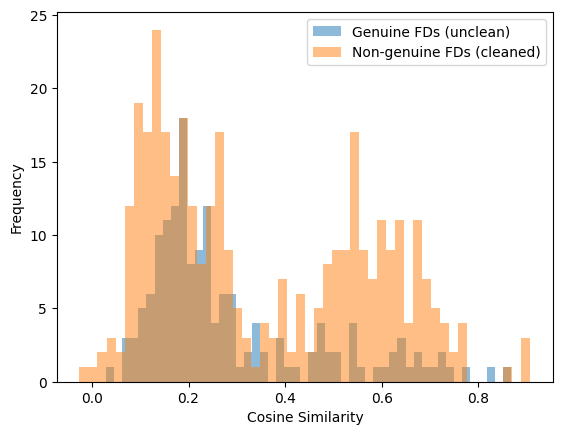

In [131]:
import matplotlib.pyplot as plt
plt.hist(gen_similarites_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_similarites_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [132]:
type(gen_similarites_unclean)

pandas.core.series.Series

In [133]:
texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = model.encode(texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.0000001 , 0.17218286],
       [0.17218286, 1.        ]], dtype=float32)

In [134]:
import Levenshtein
print(Levenshtein.distance(texts[0], texts[1]))

12


In [135]:
def build_levenshtein(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    min_distance = float('inf')
    for lhs_elem in lhs:
        distance = Levenshtein.distance(lhs_elem, rhs)
        if distance < min_distance:
            min_distance = distance
    return min_distance

In [136]:
gen_leven_unclean = gen_data.apply(build_levenshtein, axis=1)
ungen_leven_clean = nongen_data.apply(build_levenshtein, axis=1)

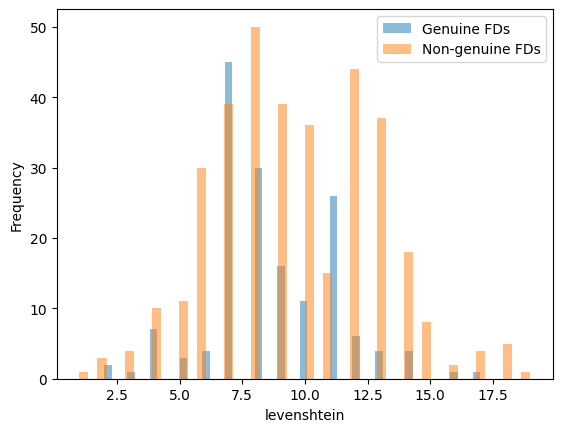

In [137]:
import matplotlib.pyplot as plt
plt.hist(gen_leven_unclean, bins=50, alpha=0.5, label='Genuine FDs')
plt.hist(ungen_leven_clean, bins=50, alpha=0.5, label='Non-genuine FDs')
plt.xlabel('levenshtein')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [138]:
def longest_common_substring(a: str, b: str) -> str:
    if not a or not b:
        return ""

    dp = [0] * (len(b) + 1)
    best_len = 0
    best_end = 0 

    for i in range(1, len(a) + 1):
        prev_diag = 0
        for j in range(1, len(b) + 1):
            tmp = dp[j]
            if a[i - 1] == b[j - 1]:
                dp[j] = prev_diag + 1
                if dp[j] > best_len:
                    best_len = dp[j]
                    best_end = i
            else:
                dp[j] = 0
            prev_diag = tmp

    return a[best_end - best_len:best_end]



In [139]:
def build_lcs(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    max_distance = 0
    for lhs_elem in lhs:
        distance = len(longest_common_substring(lhs_elem, rhs))
        if distance > max_distance:
            max_distance = distance
    return max_distance

In [140]:
gen_lcs_unclean = gen_data.apply(build_lcs, axis=1)
ungen_lcs_clean = nongen_data.apply(build_lcs, axis=1)

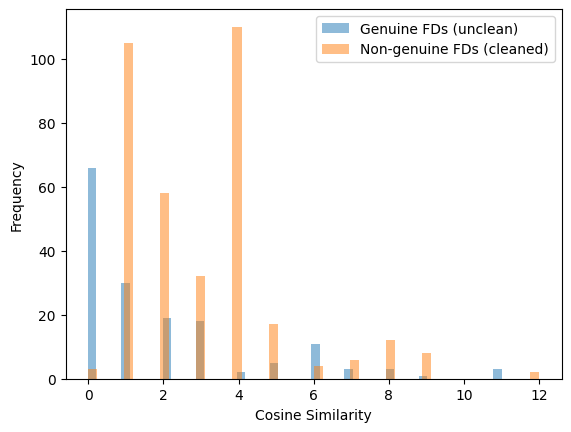

In [141]:
import matplotlib.pyplot as plt
plt.hist(gen_lcs_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_lcs_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [142]:
df = pd.DataFrame()

In [143]:
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

In [144]:
df

,cosine_sim,lcs,leven,is_genuine
0,0.681850,6,2,True
1,0.640750,6,9,True
2,0.620726,6,2,True
3,0.503650,6,9,True
4,0.191531,3,14,True
...,...,...,...,...
513,0.193200,0,11,False
514,0.673747,1,1,False
515,0.720724,1,2,False
516,0.678205,1,2,False


In [145]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

X = df[["cosine_sim", "lcs", "leven"]]
y = df["is_genuine"]

In [146]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [147]:
clf = DecisionTreeClassifier(
    max_depth=5,        # prevents overfitting
    min_samples_leaf=5, # smoother splits
    random_state=42
)

clf.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42)

In [148]:
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.7403846153846154
              precision    recall  f1-score   support

       False       0.82      0.81      0.81        72
        True       0.58      0.59      0.58        32

    accuracy                           0.74       104
   macro avg       0.70      0.70      0.70       104
weighted avg       0.74      0.74      0.74       104



In [149]:
import pandas as pd

importance = pd.Series(
    clf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)


lcs           0.787377
cosine_sim    0.135488
leven         0.077135
dtype: float64


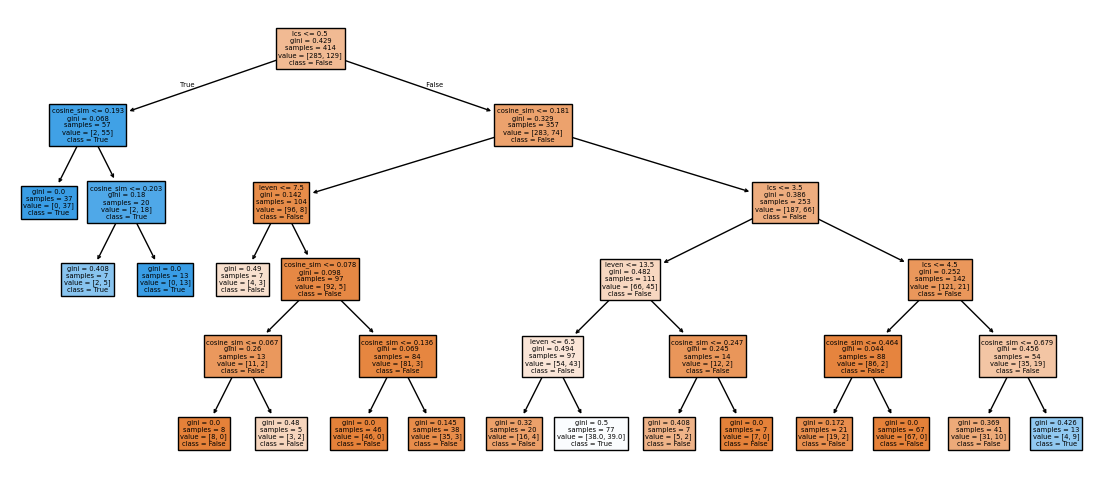

In [150]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["False", "True"],
    filled=True
)
plt.show()


In [151]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [152]:
clf = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",  # helpful if classes are imbalanced
    random_state=42
)

clf.fit(X_train_scaled, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [153]:
y_pred = clf.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.7019230769230769
              precision    recall  f1-score   support

       False       0.82      0.74      0.77        72
        True       0.51      0.62      0.56        32

    accuracy                           0.70       104
   macro avg       0.66      0.68      0.67       104
weighted avg       0.72      0.70      0.71       104



In [154]:
y_pred

array([False, False,  True,  True, False, False, False,  True,  True,
       False, False, False, False,  True,  True,  True,  True,  True,
       False, False,  True, False,  True, False, False, False, False,
        True,  True,  True, False, False, False, False,  True,  True,
       False, False, False, False, False, False, False, False, False,
        True, False, False,  True,  True, False,  True,  True, False,
       False,  True, False, False,  True, False, False, False,  True,
        True,  True,  True, False, False,  True, False, False, False,
        True,  True, False, False,  True, False,  True, False, False,
       False,  True, False,  True, False,  True, False, False, False,
       False, False,  True, False, False, False, False,  True, False,
       False, False,  True, False,  True])

In [155]:
raw_texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = model.encode(raw_texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.0000001 , 0.17218286],
       [0.17218286, 1.        ]], dtype=float32)

In [156]:
Levenshtein.distance(raw_texts[0], raw_texts[1])

12

In [157]:
longest_common_substring(raw_texts[0], raw_texts[1])

'Delay'

In [158]:
import re

CAMEL_CASE_PATTERN = re.compile(
    r'''
    [A-Z]+(?=[A-Z][a-z]) |   # Acronyms followed by Capitalized words
    [A-Z]?[a-z]+ |           # Capitalized or lowercase words
    [A-Z]+ |                 # All-caps words
    \d+                      # Numbers
    ''',
    re.VERBOSE
)

def camel_case_tokenize(text: str) -> list[str]:
    return CAMEL_CASE_PATTERN.findall(text)


In [159]:
texts = camel_case_tokenize(raw_texts[0]) + camel_case_tokenize(raw_texts[1])
print(texts)

['Dep', 'Delay', 'Departure', 'Delay', 'Groups']


In [160]:
embeddings = model.encode(texts, normalize_embeddings=True)
sim = cosine_similarity(embeddings)

In [161]:
sim

array([[1.0000002 , 0.23588921, 0.2667036 , 0.23588921, 0.2343167 ],
       [0.23588921, 0.9999997 , 0.27791515, 0.9999997 , 0.29369226],
       [0.2667036 , 0.27791515, 1.0000001 , 0.27791515, 0.26653332],
       [0.23588921, 0.9999997 , 0.27791515, 0.9999997 , 0.29369226],
       [0.2343167 , 0.29369226, 0.26653332, 0.29369226, 1.0000001 ]],
      dtype=float32)

In [162]:
import numpy as np
levenshteins = np.array([], dtype=np.int16)
for t1 in texts:
    row = []
    for t2 in texts:
        row.append(Levenshtein)